# 3. Errores y explicaciones de los modelos de referencia

Primero revisamos qué defectos omiten los tres modelos y en qué casos dan falsas alarmas. Después comparamos sus mapas para ver qué zonas señalan cuando analizan las mismas imágenes de validación.

In [23]:
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torchvision.transforms.functional import gaussian_blur

from photovoltaic_xai import CLASS_NAMES, MODEL_NAMES, PROTOCOL_ID
from photovoltaic_xai.dataset import PairedELTransform, PVELADDataset
from photovoltaic_xai.models import load_run, load_trained_model, save_json
from photovoltaic_xai.notebook_support import project_root
from photovoltaic_xai.preparation import load_preparation
from photovoltaic_xai.variant import file_hash
from photovoltaic_xai.xai import (
    cam,
    evaluate_xai_image,
    localization_metrics,
    make_rise_bank,
    pair_random_curves,
    perturbation_curve,
    randomized_model,
    select_xai_subset,
    xai_key,
)

## Datos y configuración del análisis

Cargamos la partición de validación preparada en la notebook 01 y las predicciones y umbrales guardados en la 02. Reutilizamos el mismo preprocesado de validación y fijamos los parámetros del análisis de los mapas.

In [24]:
PROJECT_ROOT = project_root()
EXPERIMENT_DIR = PROJECT_ROOT / "outputs/experiments"
XAI_DIR = PROJECT_ROOT / "outputs/xai" / PROTOCOL_ID
DIAGNOSTIC_DIR = PROJECT_ROOT / "outputs/refinement/validation_diagnostics"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
XAI_CONFIG = {
    "per_class": 20,
    "healthy": 20,
    "n_masks": 4000,
    "grid_size": 16,
    "seed": 42,
    "mask_batch_size": 4,
}
DIAGNOSTIC_CONFIG = {
    "per_class": 2,
    "healthy": 4,
    "selection_seed": 42,
    "control_seeds": [43, 44],
    "blur_kernel": 51,
    "blur_sigma": 12.0,
}
prepared = load_preparation(PROJECT_ROOT)
normalization = prepared["normalization"]
transform = PairedELTransform(
    normalization["image_size"], mean=normalization["mean"], std=normalization["std"]
)
validation_records = [record for record in prepared["records"] if record["split"] == "val"]
validation_by_id = {record["id"]: record for record in validation_records}
runs, predictions = {}, {}
for model_name in MODEL_NAMES:
    runs[model_name], predictions[model_name] = load_run(EXPERIMENT_DIR / model_name, prepared)
print("Imágenes de validación:", len(validation_records), "· Dispositivo:", device)

Imágenes de validación: 5000 · Dispositivo: cuda


## Errores por defecto

Aplicamos los umbrales guardados y comparamos las predicciones con las etiquetas. Por modelo y defecto, la tabla cuenta las detecciones correctas (TP), las omisiones (FN), las falsas alarmas (FP) y los aciertos cuando el defecto está ausente (TN).

In [25]:
errors = []
confusion = []

for model_name in MODEL_NAMES:
    saved = predictions[model_name]
    labels = saved["labels"].astype(bool)
    probabilities = saved["probabilities"]
    thresholds = np.asarray(runs[model_name]["metrics"]["thresholds"])
    predicted = probabilities >= thresholds

    # Count the four outcomes independently for each defect.
    for class_index, defect in enumerate(CLASS_NAMES):
        actual = labels[:, class_index]
        decision = predicted[:, class_index]
        confusion.append(
            {
                "model": model_name,
                "defect": defect,
                "TP": int((actual & decision).sum()),
                "FN": int((actual & ~decision).sum()),
                "FP": int((~actual & decision).sum()),
                "TN": int((~actual & ~decision).sum()),
            }
        )

    # Keep each error together with its true co-occurring defects.
    for sample_index, class_index in np.argwhere(labels != predicted):
        cardinality = int(labels[sample_index].sum())
        if cardinality == 0:
            image_type = "healthy"
        elif cardinality == 1:
            image_type = "single_type"
        else:
            image_type = "multilabel"

        present_defects = np.asarray(CLASS_NAMES)[labels[sample_index]]
        error_type = "false_negative" if labels[sample_index, class_index] else "false_positive"
        errors.append(
            {
                "model": model_name,
                "id": saved["ids"][sample_index],
                "defect": CLASS_NAMES[class_index],
                "error": error_type,
                "probability": probabilities[sample_index, class_index],
                "image_type": image_type,
                "present_defects": ", ".join(present_defects) or "healthy",
            }
        )

confusion = pd.DataFrame(confusion)
error_columns = ["model", "id", "defect", "error", "probability", "image_type", "present_defects"]
errors = pd.DataFrame(errors, columns=error_columns)

display(confusion)

,model,defect,TP,FN,FP,TN
0,efficientnet_b0,crack,332,131,43,4494
1,efficientnet_b0,finger,1829,75,38,3058
2,efficientnet_b0,black_core,681,5,5,4309
3,efficientnet_b0,thick_line,251,45,31,4673
4,efficientnet_b0,short_circuit,197,0,1,4802
5,efficientnet_b0,horizontal_dislocation,119,0,0,4881
6,convnext_tiny,crack,370,93,74,4463
7,convnext_tiny,finger,1837,67,67,3029
8,convnext_tiny,black_core,680,6,5,4309
9,convnext_tiny,thick_line,259,37,44,4660


La grieta es el defecto con más omisiones en los tres modelos. Swin omite dos grietas menos que ConvNeXt y genera 31 falsas alarmas más para esa clase.

### Contexto de los errores

Para cada modelo y clase, la tabla desglosa las omisiones (`false_negative`) y las falsas alarmas (`false_positive`) según los defectos anotados (`present_defects`). `image_type` indica si la imagen es sana o tiene uno o varios tipos de defecto. `error_count` cuenta las imágenes de cada grupo. Una imagen puede aparecer en varias filas si hay errores en distintas clases o modelos.

In [26]:
error_summary = (
    errors.groupby(["model", "defect", "error", "image_type", "present_defects"])
    .size()
    .rename("error_count")
    .reset_index()
)

display(error_summary)

,model,defect,error,image_type,present_defects,error_count
0,convnext_tiny,black_core,false_negative,multilabel,"crack, black_core",1
1,convnext_tiny,black_core,false_negative,multilabel,"crack, finger, black_core",1
2,convnext_tiny,black_core,false_negative,multilabel,"finger, black_core",1
3,convnext_tiny,black_core,false_negative,single_type,black_core,3
4,convnext_tiny,black_core,false_positive,multilabel,"crack, finger",1
...,...,...,...,...,...,...
109,swin_t,thick_line,false_negative,single_type,thick_line,6
110,swin_t,thick_line,false_positive,healthy,healthy,11
111,swin_t,thick_line,false_positive,multilabel,"crack, finger",2
112,swin_t,thick_line,false_positive,single_type,crack,4


En los tres modelos, más de la mitad de las grietas omitidas aparecen en imágenes con una interrupción de dedo. Entre las omisiones de grieta de ConvNeXt, las filas que incluyen `finger` en `present_defects` suman 61 (58 + 3).

## Selección de imágenes para las explicaciones

Seleccionamos las imágenes de validación según sus etiquetas, con un cupo de 20 por defecto y otro de 20 sanas. Para las imágenes con defectos, usamos las que tienen cajas válidas. Los tres modelos se analizan con la misma muestra y el mismo banco de máscaras RISE.

In [27]:
selected_ids = select_xai_subset(
    validation_records,
    per_class=XAI_CONFIG["per_class"],
    healthy=XAI_CONFIG["healthy"],
    seed=XAI_CONFIG["seed"],
)
selected_records = [validation_by_id[identifier] for identifier in selected_ids]
xai_dataset = PVELADDataset(selected_records, PROJECT_ROOT, transform, return_masks=True)
XAI_DIR.mkdir(parents=True, exist_ok=True)
selection_path = XAI_DIR / "evaluation_val.json"
bank_path = XAI_DIR / "rise_bank_val.pt"
checkpoint_hashes = {name: file_hash(EXPERIMENT_DIR / name / "best.pt") for name in MODEL_NAMES}
selection = {
    "data_fingerprint": prepared["data_fingerprint"],
    "split": "val",
    "ids": selected_ids,
    "config": XAI_CONFIG,
    "models": list(MODEL_NAMES),
}

recorded = json.loads(selection_path.read_text()) if selection_path.exists() else None
selection_compatible = recorded is not None
if recorded is not None:
    selection_compatible = all(recorded.get(key) == value for key, value in selection.items())
    selection_compatible &= recorded.get("checkpoint_sha256") == checkpoint_hashes
    if not selection_compatible:
        raise ValueError("Saved XAI inputs differ; preserve those results and use a new XAI_DIR")
bank_config = {
    "n_masks": XAI_CONFIG["n_masks"],
    "grid_size": XAI_CONFIG["grid_size"],
    "p": 0.5,
    "seed": XAI_CONFIG["seed"],
    "image_size": [normalization["image_size"]] * 2,
}
if bank_path.exists():
    rise_bank = torch.load(bank_path, map_location="cpu", weights_only=True)
    if rise_bank["config"] != bank_config:
        raise ValueError("Saved RISE masks use another configuration")
else:
    rise_bank = make_rise_bank(
        (normalization["image_size"],) * 2,
        n_masks=XAI_CONFIG["n_masks"],
        grid_size=XAI_CONFIG["grid_size"],
        p=0.5,
        seed=XAI_CONFIG["seed"],
    )
    torch.save(rise_bank, bank_path)
if recorded is not None and recorded.get("rise") != bank_config:
    raise ValueError("Saved XAI selection and RISE configuration differ")
selection.update(rise=bank_config, checkpoint_sha256=checkpoint_hashes)
# Commit selection.json only after its aggregate tables are complete below.
print(
    "Imágenes para XAI:", len(selected_records), "· Máscaras RISE:", rise_bank["config"]["n_masks"]
)

Imágenes para XAI: 140 · Máscaras RISE: 4000


## Localización y curvas de eliminación

Grad-CAM y Layer-CAM usan los gradientes de la puntuación de cada defecto para estimar qué zonas de la imagen influyen en la predicción. RISE construye el mapa a partir de las probabilidades que obtiene al ocultar zonas con máscaras aleatorias.

Comprobamos si las zonas destacadas coinciden con las cajas anotadas y cómo cambia la probabilidad del defecto al ocultar píxeles. Los ocultamos en pasos del 5 %, empezando por los que más destaca cada mapa. Como referencia, repetimos la prueba con un orden aleatorio común a los tres métodos.

In [28]:
location_path = XAI_DIR / "localization_val.csv"
curves_path = XAI_DIR / "perturbations_val.csv"
expected_keys = {
    (name, record["id"], CLASS_NAMES[c], method)
    for name in MODEL_NAMES
    for record in selected_records
    for c in range(6)
    if record["labels"][c] or not any(record["labels"])
    for method in ("gradcam", "layercam", "rise")
}
main_complete = selection_compatible and location_path.exists() and curves_path.exists()
if main_complete:
    location = pd.read_csv(location_path)
    curves = pd.DataFrame(pair_random_curves(pd.read_csv(curves_path).to_dict("records")))
    keys = ["run", "id", "class", "method"]
    main_complete = (
        not location.duplicated(keys).any()
        and set(location[keys].itertuples(index=False, name=None)) == expected_keys
    )
    points = curves.groupby(keys + ["random_order"]).fraction.agg(list)
    main_complete &= (
        len(points) == 2 * len(expected_keys)
        and set(curves.random_order) == {False, True}
        and set(curves[keys].itertuples(index=False, name=None)) == expected_keys
        and all(len(v) == 21 and np.allclose(sorted(v), np.linspace(0, 1, 21)) for v in points)
    )
if not main_complete:
    spatial_rows, deletion_rows = [], []
    for model_name in MODEL_NAMES:
        model = None
        thresholds = np.asarray(runs[model_name]["metrics"]["thresholds"])
        inputs = {
            "data_fingerprint": prepared["data_fingerprint"],
            "ids": selected_ids,
            "checkpoint_sha256": checkpoint_hashes[model_name],
            "thresholds": thresholds.tolist(),
            "config": XAI_CONFIG,
        }
        inputs_key = xai_key(inputs)
        for index, record in enumerate(selected_records):
            image_path = XAI_DIR / "images" / model_name / f"{record['id']}.json"
            cached = json.loads(image_path.read_text()) if image_path.is_file() else None
            if cached is not None and cached.get("inputs_key") != inputs_key:
                raise ValueError(f"Los datos del mapa guardado no coinciden: {image_path}")
            if cached is None:
                if model is None:
                    model, _ = load_trained_model(
                        EXPERIMENT_DIR / model_name, prepared, device=device
                    )
                sample = xai_dataset[index]
                image, valid = sample["image"].to(device), sample["valid_mask"].to(device)
                rows, image_curves, _ = evaluate_xai_image(
                    model_name,
                    model,
                    image,
                    sample,
                    valid,
                    thresholds,
                    rise_bank,
                    lambda c, method, net=model, pixels=image: cam(net, pixels, c, method=method),
                    batch_size=XAI_CONFIG["mask_batch_size"],
                )
                cached = {"inputs_key": inputs_key, "spatial": rows, "curves": image_curves}
                save_json(image_path, cached)
            spatial_rows.extend(cached["spatial"])
            deletion_rows.extend(cached["curves"])
            if (index + 1) % 20 == 0:
                print(f"{model_name}: {index + 1}/{len(selected_records)} imágenes")
        del model
    location = pd.DataFrame(spatial_rows)
    curves = pd.DataFrame(pair_random_curves(deletion_rows))
    location.to_csv(location_path, index=False)
    pd.DataFrame(deletion_rows).to_csv(curves_path, index=False)
    if not selection_compatible:
        save_json(selection_path, selection)
print(f"XAI: {len(location)} filas de localización y {len(curves)} puntos de las curvas")

efficientnet_b0: 20/140 imágenes
efficientnet_b0: 40/140 imágenes
efficientnet_b0: 60/140 imágenes
efficientnet_b0: 80/140 imágenes
efficientnet_b0: 100/140 imágenes
efficientnet_b0: 120/140 imágenes
efficientnet_b0: 140/140 imágenes
convnext_tiny: 20/140 imágenes
convnext_tiny: 40/140 imágenes
convnext_tiny: 60/140 imágenes
convnext_tiny: 80/140 imágenes
convnext_tiny: 100/140 imágenes
convnext_tiny: 120/140 imágenes
convnext_tiny: 140/140 imágenes
swin_t: 20/140 imágenes
swin_t: 40/140 imágenes
swin_t: 60/140 imágenes
swin_t: 80/140 imágenes
swin_t: 100/140 imágenes
swin_t: 120/140 imágenes
swin_t: 140/140 imágenes
XAI: 2529 filas de localización y 106218 puntos de las curvas


### Localización media por modelo y método

La tabla compara dos métricas. Pointing Game indica qué proporción de los puntos de máxima intensidad del mapa cae dentro de las cajas del defecto. La energía corregida mide cuánto peso concentra el mapa en las cajas en relación con su área. En las imágenes sanas, ambas métricas aparecen como `NaN` porque no hay cajas.

In [29]:
display(
    location.groupby(["run", "method", "healthy"])[["pointing_game", "energy_corrected"]].mean()
)

pointing_game  energy_corrected
run             method   healthy                                 
convnext_tiny   gradcam  False         0.461180          0.015593
                         True               NaN               NaN
                layercam False         0.490683          0.052306
                         True               NaN               NaN
                rise     False         0.670807          0.000739
                         True               NaN               NaN
efficientnet_b0 gradcam  False         0.370342         -0.065643
                         True               NaN               NaN
                layercam False         0.636646         -0.198911
                         True               NaN               NaN
                rise     False         0.639752          0.000458
                         True               NaN               NaN
swin_t          gradcam  False         0.503591          0.045395
                         True               NaN               NaN
                layercam False         0.708075          0.060458
                         True               NaN               NaN
                rise     False         0.652174          0.000607
                         True               NaN               NaN

Layer-CAM con Swin-Tiny alcanza el mayor Pointing Game (70,81 %). En EfficientNet y ConvNeXt, RISE obtiene la mejor puntuación en esa métrica.

### Localización por defecto y decisión

Separamos los resultados según si el modelo activó la etiqueta (`predicted_positive`). Así podemos comparar los mapas de un defecto cuando el modelo lo detecta y cuando lo omite. Para cada métrica se muestra la media (`mean`) y cuántas veces pudo calcularse (`count`).

In [30]:
# Keep prediction status and missing-result reasons in the spatial summary.
spatial_summary = location.groupby(["run", "method", "class", "healthy", "predicted_positive"])[
    ["pointing_game", "energy", "energy_corrected"]
].agg(["mean", "count"])
display(spatial_summary)

pointing_game  \
                                                                        mean   
run           method  class         healthy predicted_positive                 
convnext_tiny gradcam black_core    False   False                   0.000000   
                                            True                    0.900000   
                                    True    False                        NaN   
                      crack         False   False                   0.000000   
                                            True                    0.640000   
...                                                                      ...   
swin_t        rise    short_circuit False   True                    1.000000   
                                    True    False                        NaN   
                      thick_line    False   False                   0.333333   
                                            True                    0.761905   
                                    True    False                        NaN   

                                                                      \
                                                               count   
run           method  class         healthy predicted_positive         
convnext_tiny gradcam black_core    False   False                  1   
                                            True                  20   
                                    True    False                  0   
                      crack         False   False                  2   
                                            True                  25   
...                                                              ...   
swin_t        rise    short_circuit False   True                  20   
                                    True    False                  0   
                      thick_line    False   False                  3   
                                            True                  21   
                                    True    False                  0   

                                                                  energy  \
                                                                    mean   
run           method  class         healthy predicted_positive             
convnext_tiny gradcam black_core    False   False               0.260093   
                                            True                0.695175   
                                    True    False                    NaN   
                      crack         False   False               0.044294   
                                            True                0.208254   
...                                                                  ...   
swin_t        rise    short_circuit False   True                0.888616   
                                    True    False                    NaN   
                      thick_line    False   False               0.004425   
                                            True                0.006423   
                                    True    False                    NaN   

                                                                      \
                                                               count   
run           method  class         healthy predicted_positive         
convnext_tiny gradcam black_core    False   False                  1   
                                            True                  20   
                                    True    False                  0   
                      crack         False   False                  2   
                                            True                  25   
...                                                              ...   
swin_t        rise    short_circuit False   True                  20   
                                    True    False                  0   
                      thick_line    False   False                  3   
    

Entre las 25 grietas que detecta ConvNeXt en esta muestra, el máximo de Grad-CAM cae dentro de las cajas en 16. En las dos que omite, el máximo queda fuera.

### Valores de localización que faltan

La tabla cuenta los casos por motivo. Si faltan cajas o el mapa es nulo, quedan vacías las métricas de localización. Si las cajas cubren toda la zona útil de la imagen, solo falta la energía corregida. Un motivo vacío (`NaN`) indica que se calcularon todas las métricas.

In [31]:
missing_reasons = location.groupby(["run", "method", "reason"], dropna=False).size().rename("Casos")
display(missing_reasons)

run              method    reason             
convnext_tiny    gradcam   no_class_annotation    120
                           NaN                    161
                 layercam  no_class_annotation    120
                           NaN                    161
                 rise      no_class_annotation    120
                           NaN                    161
efficientnet_b0  gradcam   no_class_annotation    120
                           NaN                    161
                 layercam  no_class_annotation    120
                           NaN                    161
                 rise      no_class_annotation    120
                           NaN                    161
swin_t           gradcam   no_class_annotation    120
                           NaN                    161
                 layercam  no_class_annotation    120
                           NaN                    161
                 rise      no_class_annotation    120
                           NaN     

Las métricas de localización solo faltan en las 120 salidas de las 20 imágenes sanas. Se pudieron calcular para los 161 pares de imagen y defecto anotado en todos los modelos y métodos.

### Energía dentro de las cajas

El gráfico compara la energía corregida media para los defectos anotados. Una barra por encima de cero indica que los mapas concentran dentro de las cajas más peso del que les correspondería por su área.

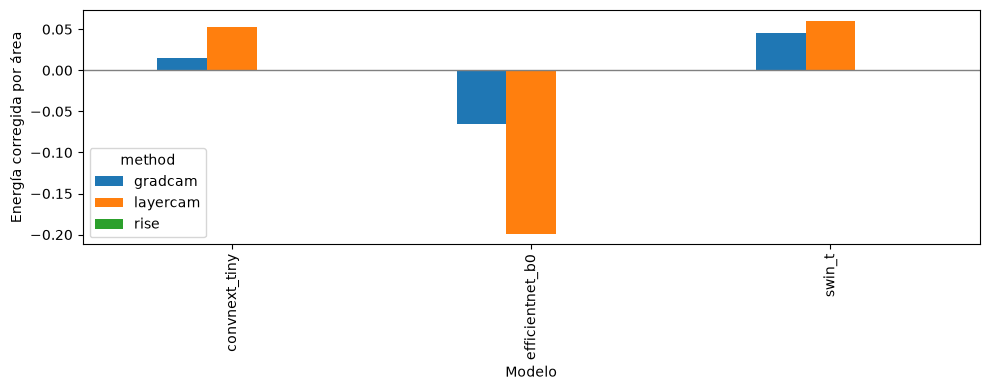

In [32]:
positive_location = location.loc[~location.healthy]
if not positive_location.empty:
    average_energy = positive_location.groupby(["run", "method"])["energy_corrected"].mean()
    average_energy.unstack().plot.bar(
        figsize=(10, 4), ylabel="Energía corregida por área", xlabel="Modelo"
    )
    plt.axhline(0, color="gray", linewidth=1)
    plt.tight_layout()
    plt.show()

Layer-CAM obtiene la mayor energía corregida en ConvNeXt y Swin. Con RISE, el peso dentro de las cajas queda cerca del que corresponde a su área en los tres modelos.

### Probabilidad al ocultar píxeles

Cada columna corresponde a un modelo y la línea gris discontinua muestra el orden aleatorio. Las curvas de arriba promedian la probabilidad de los defectos anotados a medida que se ocultan píxeles. Las de abajo hacen lo mismo con las seis salidas en imágenes sanas.

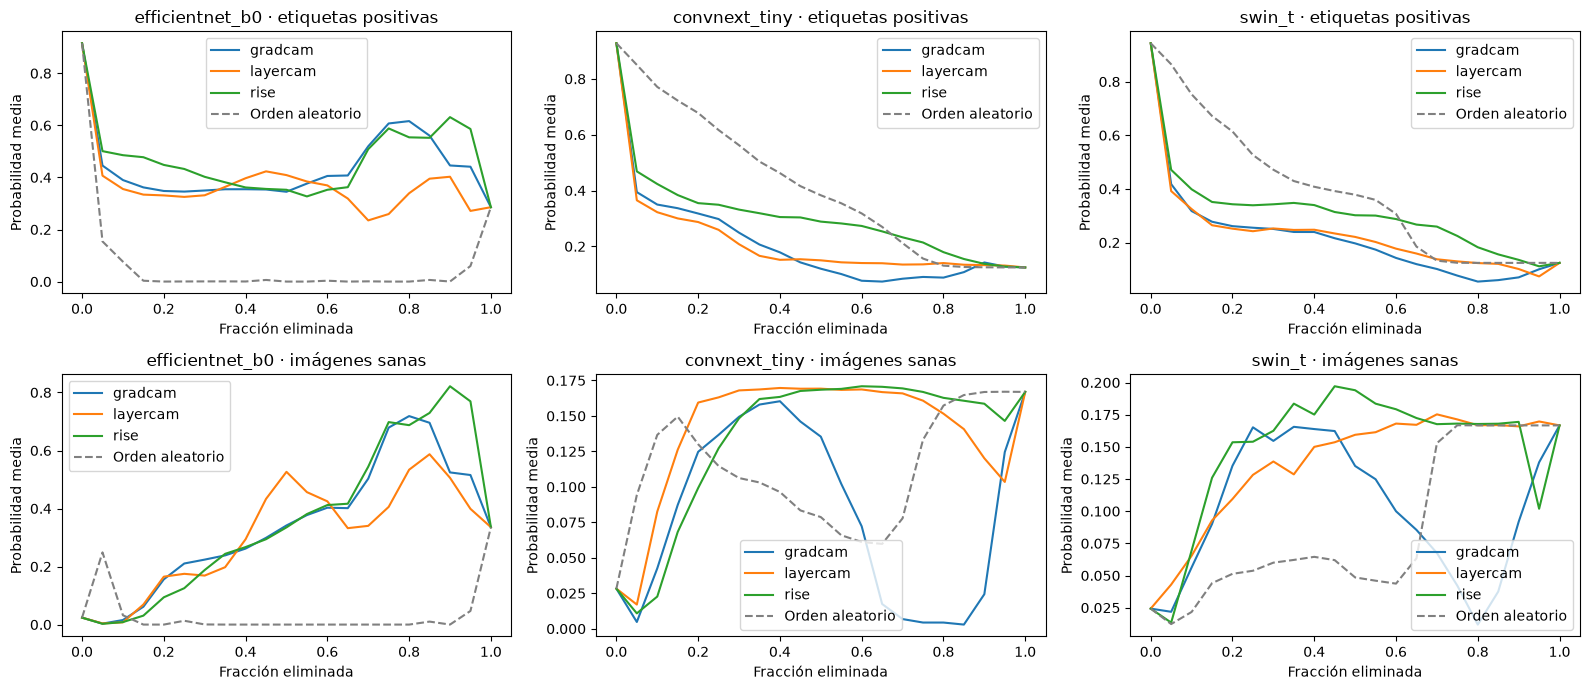

In [33]:
_, axes = plt.subplots(2, len(MODEL_NAMES), figsize=(16, 7), squeeze=False)
for row, healthy in enumerate((False, True)):
    for column, model_name in enumerate(MODEL_NAMES):
        axis = axes[row, column]
        current = curves.loc[(curves.run == model_name) & (curves.healthy == healthy)]

        for method in ("gradcam", "layercam", "rise"):
            method_curves = current.loc[(current.method == method) & ~current.random_order]
            average = method_curves.groupby("fraction")["masked_probability"].mean()
            axis.plot(average.index, average.values, label=method)

        random_curves = current.loc[(current.method == "rise") & current.random_order]
        average = random_curves.groupby("fraction")["masked_probability"].mean()
        axis.plot(average.index, average.values, "--", color="gray", label="Orden aleatorio")
        image_group = "imágenes sanas" if healthy else "etiquetas positivas"
        axis.set(
            title=model_name + " · " + image_group,
            xlabel="Fracción eliminada",
            ylabel="Probabilidad media",
        )
        axis.legend()

plt.tight_layout()
plt.show()

En los defectos anotados, ocultar los píxeles que señalan los mapas reduce más la probabilidad, en promedio, que ocultarlos al azar en ConvNeXt y Swin. En EfficientNet, el orden aleatorio produce una caída mayor. Eso motiva probar otro relleno.

## Efecto del relleno y de los pesos

Seleccionamos una muestra más pequeña de validación para dos pruebas con Grad-CAM y Layer-CAM. En la primera cambiamos el relleno de los píxeles ocultos. En la segunda comprobamos cuánto cambian los mapas al reiniciar parte de los pesos.

In [34]:
diagnostic_ids = select_xai_subset(
    validation_records,
    per_class=DIAGNOSTIC_CONFIG["per_class"],
    healthy=DIAGNOSTIC_CONFIG["healthy"],
    seed=DIAGNOSTIC_CONFIG["selection_seed"],
)
diagnostic_records = [validation_by_id[identifier] for identifier in diagnostic_ids]
diagnostic_set = PVELADDataset(diagnostic_records, PROJECT_ROOT, transform, return_masks=True)
contexts, diagnostic_compatible = {}, {}
for model_name in MODEL_NAMES:
    context = {
        "data_fingerprint": prepared["data_fingerprint"],
        "checkpoint_sha256": checkpoint_hashes[model_name],
        "config": DIAGNOSTIC_CONFIG,
        "ids": diagnostic_ids,
    }
    contexts[model_name] = context
    output = DIAGNOSTIC_DIR / model_name
    output.mkdir(parents=True, exist_ok=True)
    context_path = output / "inputs.json"
    recorded = json.loads(context_path.read_text()) if context_path.exists() else {}
    diagnostic_compatible[model_name] = all(recorded.get(k) == v for k, v in context.items())
    if context_path.exists() and not diagnostic_compatible[model_name]:
        raise ValueError("Saved diagnostic inputs differ; existing results are preserved")
    # Commit inputs.json after all three diagnostic blocks finish below.
print("Imágenes de diagnóstico:", len(diagnostic_records))

Imágenes de diagnóstico: 16


Calculamos o recuperamos los mapas y las predicciones de los modelos entrenados para esta muestra. Nos sirven de referencia para las dos pruebas.

In [35]:
for model_name in MODEL_NAMES:
    output = DIAGNOSTIC_DIR / model_name
    files = [output / name for name in ("maps.pt", "reference_predictions.csv")]
    if diagnostic_compatible[model_name] and all(path.is_file() for path in files):
        print(model_name, "· Mapas de referencia recuperados")
        continue

    model = None
    maps, prediction_rows = {}, []
    started = time.perf_counter()
    for index, sample in enumerate(diagnostic_set, start=1):
        image_path = output / "reference_images" / f"{sample['id']}.pt"
        cached = (
            torch.load(image_path, map_location="cpu", weights_only=True)
            if image_path.exists()
            else None
        )
        if cached is not None:
            if cached.get("inputs") != contexts[model_name]:
                raise ValueError(
                    "Saved diagnostic image inputs differ; existing results are preserved"
                )
            maps.update(cached["maps"])
            prediction_rows.extend(cached["predictions"])
            continue
        if model is None:
            model, _ = load_trained_model(EXPERIMENT_DIR / model_name, prepared, device=device)
        first_prediction = len(prediction_rows)
        image = sample["image"].to(device)
        with torch.inference_mode():
            logits = model(image[None])[0].float().cpu()
        probabilities = logits.sigmoid()
        for class_index, defect in enumerate(CLASS_NAMES):
            prediction_rows.append(
                {
                    "id": sample["id"],
                    "class": defect,
                    "label": int(sample["labels"][class_index]),
                    "logit": float(logits[class_index]),
                    "probability": float(probabilities[class_index]),
                }
            )

        targets = torch.nonzero(sample["labels"]).flatten().tolist() or list(range(6))
        for class_index in targets:
            for method in ("gradcam", "layercam"):
                saliency = cam(model, image, class_index, method=method)
                maps[sample["id"], class_index, method] = saliency.cpu()
        image_path.parent.mkdir(parents=True, exist_ok=True)
        torch.save(
            {
                "inputs": contexts[model_name],
                "maps": {k: v for k, v in maps.items() if k[0] == sample["id"]},
                "predictions": prediction_rows[first_prediction:],
            },
            image_path.with_suffix(".pt.tmp"),
        )
        image_path.with_suffix(".pt.tmp").replace(image_path)
        print(
            f"{model_name}: mapas {index}/{len(diagnostic_set)} · {time.perf_counter() - started:.1f}s"
        )

    torch.save(maps, output / "maps.pt")
    pd.DataFrame(prediction_rows).to_csv(output / "reference_predictions.csv", index=False)
    del model, maps
    if device.type == "cuda":
        torch.cuda.empty_cache()

efficientnet_b0: mapas 1/16 · 0.1s
efficientnet_b0: mapas 2/16 · 0.2s
efficientnet_b0: mapas 3/16 · 0.2s
efficientnet_b0: mapas 4/16 · 0.3s
efficientnet_b0: mapas 5/16 · 0.4s
efficientnet_b0: mapas 6/16 · 0.4s
efficientnet_b0: mapas 7/16 · 0.5s
efficientnet_b0: mapas 8/16 · 0.5s
efficientnet_b0: mapas 9/16 · 0.6s
efficientnet_b0: mapas 10/16 · 0.6s
efficientnet_b0: mapas 11/16 · 0.7s
efficientnet_b0: mapas 12/16 · 0.7s
efficientnet_b0: mapas 13/16 · 0.7s
efficientnet_b0: mapas 14/16 · 0.7s
efficientnet_b0: mapas 15/16 · 0.8s
efficientnet_b0: mapas 16/16 · 0.8s
convnext_tiny: mapas 1/16 · 0.2s
convnext_tiny: mapas 2/16 · 0.3s
convnext_tiny: mapas 3/16 · 0.3s
convnext_tiny: mapas 4/16 · 0.4s
convnext_tiny: mapas 5/16 · 0.5s
convnext_tiny: mapas 6/16 · 0.6s
convnext_tiny: mapas 7/16 · 0.6s
convnext_tiny: mapas 8/16 · 0.7s
convnext_tiny: mapas 9/16 · 0.7s
convnext_tiny: mapas 10/16 · 0.8s
convnext_tiny: mapas 11/16 · 0.8s
convnext_tiny: mapas 12/16 · 0.8s
convnext_tiny: mapas 13/16 · 0.9s


Repetimos el borrado usando dos rellenos, la intensidad media del conjunto de entrenamiento y una versión desenfocada de la imagen. Con cada uno ocultamos los píxeles según el mapa y en orden aleatorio.

In [36]:
for model_name in MODEL_NAMES:
    output = DIAGNOSTIC_DIR / model_name
    if diagnostic_compatible[model_name] and (output / "perturbations.csv").is_file():
        print(model_name, "· Curvas de eliminación recuperadas")
        continue

    model = None
    maps = torch.load(output / "maps.pt", map_location="cpu", weights_only=True)
    curve_rows = []
    started = time.perf_counter()
    for index, sample in enumerate(diagnostic_set, start=1):
        image_path = output / "perturbation_images" / f"{sample['id']}.json"
        cached = json.loads(image_path.read_text()) if image_path.exists() else None
        if cached is not None and cached.get("inputs") != contexts[model_name]:
            raise ValueError("Saved diagnostic image inputs differ; existing results are preserved")
        if cached is not None and cached.get("inputs") == contexts[model_name]:
            curve_rows.extend(cached["curves"])
            continue
        if model is None:
            model, _ = load_trained_model(EXPERIMENT_DIR / model_name, prepared, device=device)
        first_curve = len(curve_rows)
        image = sample["image"].to(device)
        valid = sample["valid_mask"].to(device)
        blurred = gaussian_blur(
            image,
            [DIAGNOSTIC_CONFIG["blur_kernel"]] * 2,
            [DIAGNOSTIC_CONFIG["blur_sigma"]] * 2,
        )
        baselines = {"mean": torch.zeros_like(image), "blur": blurred}
        targets = torch.nonzero(sample["labels"]).flatten().tolist() or list(range(6))

        for baseline_name, baseline in baselines.items():
            for class_index in targets:
                curves = {}
                for method in ("gradcam", "layercam"):
                    saliency = maps[sample["id"], class_index, method].to(device)
                    curves[method] = perturbation_curve(
                        model, image, class_index, saliency, valid_mask=valid, baseline=baseline
                    )
                curves["random"] = perturbation_curve(
                    model,
                    image,
                    class_index,
                    saliency,
                    valid_mask=valid,
                    baseline=baseline,
                    random_order=True,
                )
                for method, curve in curves.items():
                    for fraction, logit, probability in zip(
                        curve["fractions"], curve["logits"], curve["probabilities"], strict=True
                    ):
                        curve_rows.append(
                            {
                                "id": sample["id"],
                                "class": CLASS_NAMES[class_index],
                                "healthy": not bool(sample["labels"].any()),
                                "method": method,
                                "baseline": baseline_name,
                                "fraction": fraction,
                                "logit": logit,
                                "probability": probability,
                                "auc_probability": curve["auc_probability"],
                                "reason": curve["reason"],
                            }
                        )
        save_json(
            image_path,
            {
                "inputs": contexts[model_name],
                "curves": curve_rows[first_curve:],
            },
        )
        print(
            f"{model_name}: eliminación {index}/{len(diagnostic_set)} · {time.perf_counter() - started:.1f}s"
        )

    pd.DataFrame(curve_rows).to_csv(output / "perturbations.csv", index=False)
    del model, maps
    if device.type == "cuda":
        torch.cuda.empty_cache()

efficientnet_b0: eliminación 1/16 · 0.5s
efficientnet_b0: eliminación 2/16 · 0.9s
efficientnet_b0: eliminación 3/16 · 1.0s
efficientnet_b0: eliminación 4/16 · 2.2s
efficientnet_b0: eliminación 5/16 · 3.3s
efficientnet_b0: eliminación 6/16 · 4.4s
efficientnet_b0: eliminación 7/16 · 4.6s
efficientnet_b0: eliminación 8/16 · 5.0s
efficientnet_b0: eliminación 9/16 · 6.1s
efficientnet_b0: eliminación 10/16 · 6.5s
efficientnet_b0: eliminación 11/16 · 6.7s
efficientnet_b0: eliminación 12/16 · 6.9s
efficientnet_b0: eliminación 13/16 · 7.1s
efficientnet_b0: eliminación 14/16 · 7.3s
efficientnet_b0: eliminación 15/16 · 7.5s
efficientnet_b0: eliminación 16/16 · 7.7s
convnext_tiny: eliminación 1/16 · 1.2s
convnext_tiny: eliminación 2/16 · 2.2s
convnext_tiny: eliminación 3/16 · 2.7s
convnext_tiny: eliminación 4/16 · 5.7s
convnext_tiny: eliminación 5/16 · 8.7s
convnext_tiny: eliminación 6/16 · 11.7s
convnext_tiny: eliminación 7/16 · 12.2s
convnext_tiny: eliminación 8/16 · 13.2s
convnext_tiny: elimina

Volvemos a generar los mapas tras reiniciar por separado la cabeza de clasificación y el extractor de características. Usamos dos semillas en cada caso y comparamos los mapas con los del modelo entrenado.

In [37]:
for model_name in MODEL_NAMES:
    output = DIAGNOSTIC_DIR / model_name
    if diagnostic_compatible[model_name] and (output / "controls.csv").is_file():
        print(model_name, "· Controles de reinicio recuperados")
        continue

    original = None
    maps = torch.load(output / "maps.pt", map_location="cpu", weights_only=True)
    control_rows = []
    started = time.perf_counter()
    for scope in ("head", "backbone"):
        for seed in DIAGNOSTIC_CONFIG["control_seeds"]:
            control = None
            for sample in diagnostic_set:
                image_path = output / "control_images" / f"{scope}_{seed}_{sample['id']}.json"
                cached = json.loads(image_path.read_text()) if image_path.exists() else None
                if cached is not None and cached.get("inputs") != contexts[model_name]:
                    raise ValueError(
                        "Saved diagnostic image inputs differ; existing results are preserved"
                    )
                if cached is not None and cached.get("inputs") == contexts[model_name]:
                    control_rows.extend(cached["controls"])
                    continue
                if original is None:
                    original, _ = load_trained_model(
                        EXPERIMENT_DIR / model_name, prepared, device=device
                    )
                if control is None:
                    control = randomized_model(original, scope=scope, seed=seed)
                first_control = len(control_rows)
                image = sample["image"].to(device)
                valid = sample["valid_mask"].to(device)
                with torch.inference_mode():
                    logits = control(image[None])[0].float().cpu()
                probabilities = logits.sigmoid()
                targets = torch.nonzero(sample["labels"]).flatten().tolist() or list(range(6))
                for class_index in targets:
                    reference = sample["masks"][class_index]
                    for method in ("gradcam", "layercam"):
                        saliency = cam(control, image, class_index, method=method)
                        old = maps[sample["id"], class_index, method][sample["valid_mask"]].numpy()
                        new = saliency[valid].cpu().numpy()
                        correlation = (
                            float(np.corrcoef(old, new)[0, 1])
                            if np.std(old) > 0 and np.std(new) > 0
                            else None
                        )
                        control_rows.append(
                            {
                                "id": sample["id"],
                                "class": CLASS_NAMES[class_index],
                                "healthy": not bool(sample["labels"].any()),
                                "method": method,
                                "scope": scope,
                                "seed": seed,
                                "correlation": correlation,
                                "logit": float(logits[class_index]),
                                "probability": float(probabilities[class_index]),
                                **localization_metrics(saliency, reference, valid_mask=valid),
                            }
                        )
                save_json(
                    image_path,
                    {
                        "inputs": contexts[model_name],
                        "controls": control_rows[first_control:],
                    },
                )
            print(f"{model_name}: {scope}, semilla {seed} · {time.perf_counter() - started:.1f}s")
            del control
    pd.DataFrame(control_rows).to_csv(output / "controls.csv", index=False)
    if not diagnostic_compatible[model_name]:
        save_json(output / "inputs.json", contexts[model_name])
    del original, maps
    if device.type == "cuda":
        torch.cuda.empty_cache()

efficientnet_b0: head, semilla 43 · 1.0s
efficientnet_b0: head, semilla 44 · 2.0s
efficientnet_b0: backbone, semilla 43 · 2.9s
efficientnet_b0: backbone, semilla 44 · 3.8s
convnext_tiny: head, semilla 43 · 1.3s
convnext_tiny: head, semilla 44 · 2.4s
convnext_tiny: backbone, semilla 43 · 3.4s
convnext_tiny: backbone, semilla 44 · 4.5s
swin_t: head, semilla 43 · 1.7s
swin_t: head, semilla 44 · 3.1s
swin_t: backbone, semilla 43 · 4.4s
swin_t: backbone, semilla 44 · 5.8s


### Comparación de rellenos

Para cada relleno, restamos al área bajo la curva (AUC) de cada método la obtenida al ocultar píxeles al azar. La tabla muestra la media, la mediana y el número de comparaciones. Separamos las imágenes sanas y distinguimos si el modelo había activado la etiqueta antes del borrado.

In [38]:
all_curves, all_controls, all_reference = [], [], []
for model_name in MODEL_NAMES:
    output = DIAGNOSTIC_DIR / model_name
    all_reference.append(pd.read_csv(output / "reference_predictions.csv").assign(model=model_name))
    all_curves.append(pd.read_csv(output / "perturbations.csv").assign(model=model_name))
    all_controls.append(pd.read_csv(output / "controls.csv").assign(model=model_name))
curves = pd.concat(all_curves, ignore_index=True)
controls = pd.concat(all_controls, ignore_index=True)

# Keep initial confidence and classification status when interpreting deletion.
reference_predictions = pd.concat(all_reference, ignore_index=True)
reference_predictions["threshold"] = [
    runs[row["model"]]["metrics"]["thresholds"][CLASS_NAMES.index(row["class"])]
    for row in reference_predictions.to_dict("records")
]
reference_predictions["predicted_positive"] = (
    reference_predictions.probability >= reference_predictions.threshold
)
initial_status = reference_predictions[
    ["model", "id", "class", "probability", "predicted_positive"]
].rename(columns={"probability": "initial_probability"})
controls = controls.merge(initial_status, on=["model", "id", "class"], validate="many_to_one")

curve_units = curves.drop_duplicates(["model", "id", "class", "baseline", "method"])
random_auc = curve_units.loc[
    curve_units.method == "random", ["model", "id", "class", "baseline", "auc_probability"]
]
random_auc = random_auc.rename(columns={"auc_probability": "random_auc"})
paired = curve_units.loc[curve_units.method != "random"].merge(
    random_auc, on=["model", "id", "class", "baseline"], validate="many_to_one"
)
paired = paired.merge(initial_status, on=["model", "id", "class"], validate="many_to_one")
paired["delta_auc"] = paired.auc_probability - paired.random_auc
perturbation_summary = paired.groupby(
    ["model", "method", "class", "baseline", "healthy", "predicted_positive"]
).delta_auc.agg(["mean", "median", "count"])
display(perturbation_summary)

mean  \
model         method   class         baseline healthy predicted_positive             
convnext_tiny gradcam  black_core    blur     False   True               -0.477647   
                                              True    False               0.040755   
                                     mean     False   True               -0.186350   
                                              True    False               0.297905   
                       crack         blur     False   True               -0.188200   
...                                                                            ...   
swin_t        layercam short_circuit mean     True    False              -0.315484   
                       thick_line    blur     False   True               -0.463938   
                                              True    False              -0.111812   
                                     mean     False   True               -0.330519   
                                              True    False              -0.036908   

                                                                            median  \
model         method   class         baseline healthy predicted_positive             
convnext_tiny gradcam  black_core    blur     False   True               -0.477647   
                                              True    False               0.006344   
                                     mean     False   True               -0.186350   
                                              True    False               0.285758   
                       crack         blur     False   True               -0.188200   
...                                                                            ...   
swin_t        layercam short_circuit mean     True    False              -0.315588   
                       thick_line    blur     False   True               -0.500488   
                                              True    False              -0.001480   
                                     mean     False   True               -0.280162   
                                              True    False              -0.018076   

                                                                          count  
model         method   class         baseline healthy predicted_positive         
convnext_tiny gradcam  black_core    blur     False   True                    2  
                                              True    False                   4  
                                     mean     False   True                    2  
                                              True    False                   4  
                       crack         blur     False   True                    2  
...                                                                         ...  
swin_t        layercam short_circuit mean     True    False                   4  
                       thick_line    blur     False   True                    3  
                                              True    False                   4  
                                     mean     False   True                    3  
                                              True    False                   4  

[156 rows x 3 columns]

En los dos casos de núcleo negro que detecta ConvNeXt, la diferencia media de Grad-CAM frente al azar pasa de −0,19 con el relleno medio a −0,48 con desenfoque.

### Efecto del relleno en los defectos anotados

Cada panel compara los dos rellenos para un modelo. Una barra por debajo de cero indica que el área bajo la curva fue, en promedio, menor al ocultar los píxeles señalados por el mapa que al ocultarlos al azar.

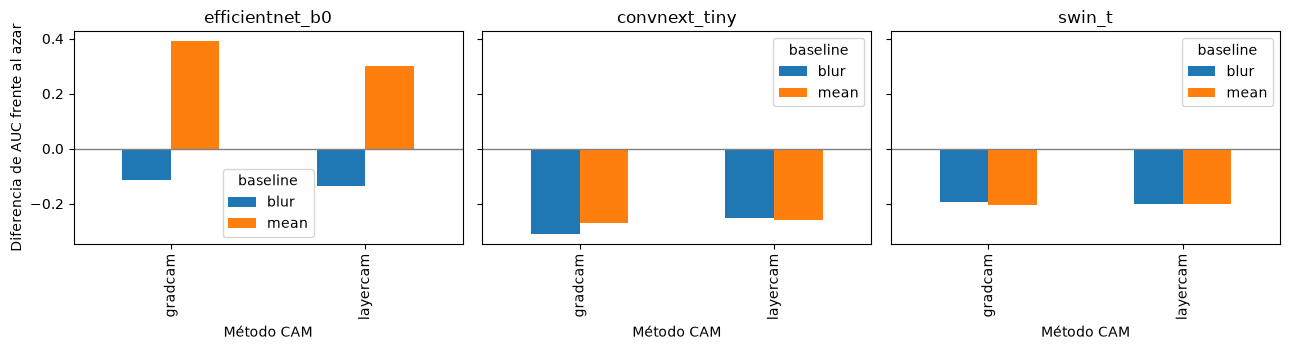

In [39]:
positive_curves = paired.loc[~paired.healthy]
_, axes = plt.subplots(1, len(MODEL_NAMES), figsize=(13, 3.6), sharey=True)
for axis, model_name in zip(axes, MODEL_NAMES):
    current = positive_curves.loc[positive_curves.model == model_name]
    current.groupby(["method", "baseline"]).delta_auc.mean().unstack().plot.bar(ax=axis)
    axis.axhline(0, color="gray", linewidth=1)
    axis.set(title=model_name, ylabel="Diferencia de AUC frente al azar", xlabel="Método CAM")
plt.tight_layout()
plt.show()

En EfficientNet, con desenfoque el borrado guiado reduce más la probabilidad que el aleatorio. Con el relleno medio ocurre lo contrario. En ConvNeXt y Swin, ambos métodos CAM obtienen un área media menor que la del orden aleatorio con los dos rellenos.

### Cambios en los mapas al reiniciar pesos

La tabla muestra la media, la mediana y cuántas correlaciones se pudieron calcular tras cada reinicio. Una correlación cercana a 1 indica que el mapa conserva un patrón parecido al del modelo entrenado.

In [40]:
control_summary = controls.groupby(
    ["model", "method", "class", "scope", "seed", "healthy", "predicted_positive"]
).correlation.agg(["mean", "median", "count"])
display(control_summary)

mean  \
model         method   class      scope    seed healthy predicted_positive             
convnext_tiny gradcam  black_core backbone 43   False   True                0.014239   
                                                True    False               0.105323   
                                           44   False   True               -0.001131   
                                                True    False              -0.018269   
                                  head     43   False   True                0.209895   
...                                                                              ...   
swin_t        layercam thick_line backbone 44   True    False              -0.085579   
                                  head     43   False   True                0.648123   
                                                True    False               0.641092   
                                           44   False   True                0.086762   
                                                True    False               0.366136   

                                                                              median  \
model         method   class      scope    seed healthy predicted_positive             
convnext_tiny gradcam  black_core backbone 43   False   True                0.014239   
                                                True    False               0.091404   
                                           44   False   True               -0.001131   
                                                True    False              -0.040283   
                                  head     43   False   True                0.209895   
...                                                                              ...   
swin_t        layercam thick_line backbone 44   True    False              -0.091770   
                                  head     43   False   True                0.687956   
                                                True    False               0.713485   
                                           44   False   True                0.076796   
                                                True    False               0.295558   

                                                                            count  
model         method   class      scope    seed healthy predicted_positive         
convnext_tiny gradcam  black_core backbone 43   False   True                    2  
                                                True    False                   4  
                                           44   False   True                    2  
                                                True    False                   4  
                                  head     43   False   True                    2  
...                                                                           ...  
swin_t        layercam thick_line backbone 44   True    False                   4  
                                  head     43   False   True                    3  
                                                True    False                   4  
                                           44   False   True                    3  
                                                True    False                   4  

[312 rows x 3 columns]

En los defectos anotados, la correlación media queda cerca de cero al reiniciar el extractor. Al reiniciar solo la cabeza, Layer-CAM conserva más parecido con el mapa entrenado que Grad-CAM.

En la [notebook 04](04_global_regional_variant.ipynb) probamos si analizar regiones con más detalle ayuda a recuperar algunas de las grietas omitidas.